In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
import os

folder_path = '/content/drive/MyDrive/Lab2_Computational_Intelligence'
part4_path = folder_path + '/Part4_Optical_Flow'

for name in ['pictures', 'frames']:
    os.makedirs(part4_path + '/' + name, exist_ok=True)

In [ ]:
import os

frames_path = part4_path + '/frames'
print(os.listdir(frames_path))

['pair1_frame1.jpg', 'pair1_frame2.jpg', 'pair2_frame1.jpg', 'pair2_frame2.jpg', 'pair3_frame1.jpg', 'pair3_frame2.jpg']


***Display the frame pairs***

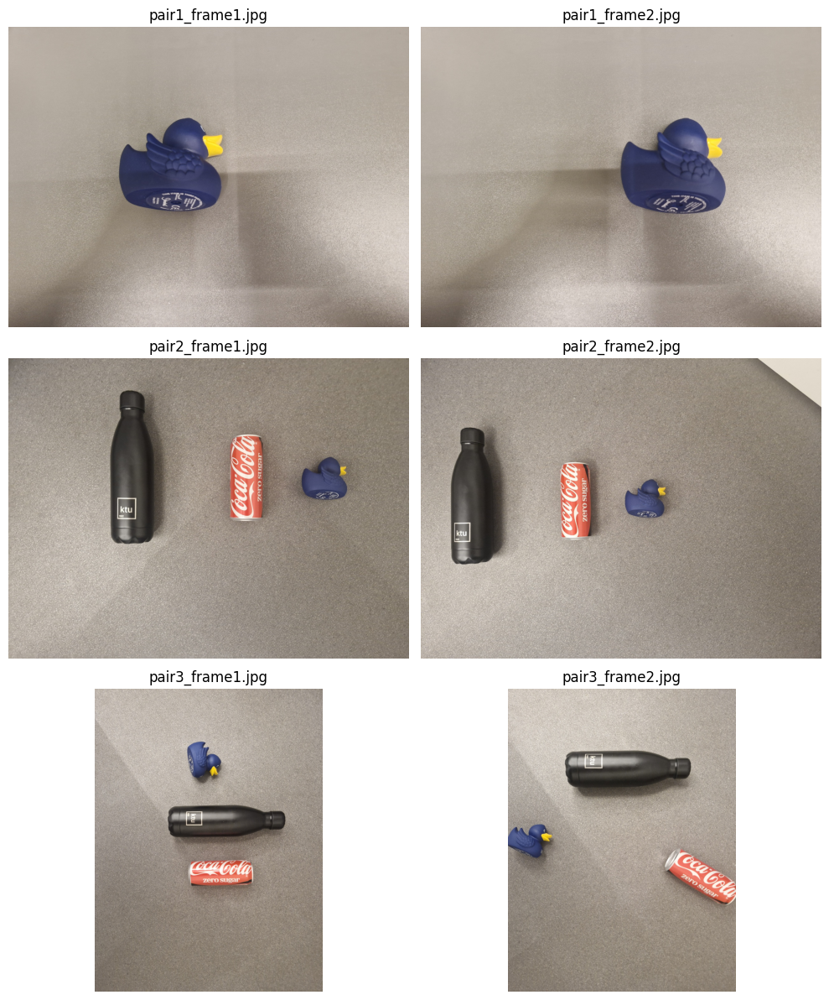

In [ ]:
import matplotlib.pyplot as plt
from PIL import Image

pairs = [
    ('pair1_frame1.jpg', 'pair1_frame2.jpg'),
    ('pair2_frame1.jpg', 'pair2_frame2.jpg'),
    ('pair3_frame1.jpg', 'pair3_frame2.jpg')
]

plt.figure(figsize=(10, 12))

for i, (img1, img2) in enumerate(pairs):
    image1 = Image.open(frames_path + '/' + img1)
    image2 = Image.open(frames_path + '/' + img2)

    plt.subplot(3, 2, 2*i + 1)
    plt.imshow(image1)
    plt.title(img1)
    plt.axis('off')

    plt.subplot(3, 2, 2*i + 2)
    plt.imshow(image2)
    plt.title(img2)
    plt.axis('off')

plt.tight_layout()
plt.show()

***Optical Flow Model Implementation***

In [ ]:
import torch
from torchvision.models.optical_flow import raft_small, Raft_Small_Weights

device = 'cuda' if torch.cuda.is_available() else 'cpu'

weights = Raft_Small_Weights.DEFAULT
model = raft_small(weights=weights).to(device)
model.eval()

transform = weights.transforms()

print("Using:", device)
print("RAFT model loaded!")

Using: cpu
RAFT model loaded!


***Calculate optical flow for all three pairs***

In [ ]:
from torchvision.transforms.functional import pil_to_tensor, resize

frames = {}
flows = {}

for i, (file1, file2) in enumerate(pairs, 1):
    img1 = Image.open(frames_path + '/' + file1).convert('RGB')
    img2 = Image.open(frames_path + '/' + file2).convert('RGB')

    w, h = img1.size
    new_w = round(w * min(1, 640 / max(w, h)) / 8) * 8
    new_h = round(h * min(1, 640 / max(w, h)) / 8) * 8

    frame1 = resize(pil_to_tensor(img1), [new_h, new_w])
    frame2 = resize(pil_to_tensor(img2), [new_h, new_w])

    input1, input2 = transform(frame1, frame2)

    with torch.no_grad():
        flow = model(
            input1.unsqueeze(0).to(device),
            input2.unsqueeze(0).to(device)
        )[-1][0]

    frames[f'pair{i}'] = (frame1, frame2)
    flows[f'pair{i}'] = flow.cpu()

    print(f'Pair {i} completed')

Pair 1 completed
Pair 2 completed
Pair 3 completed


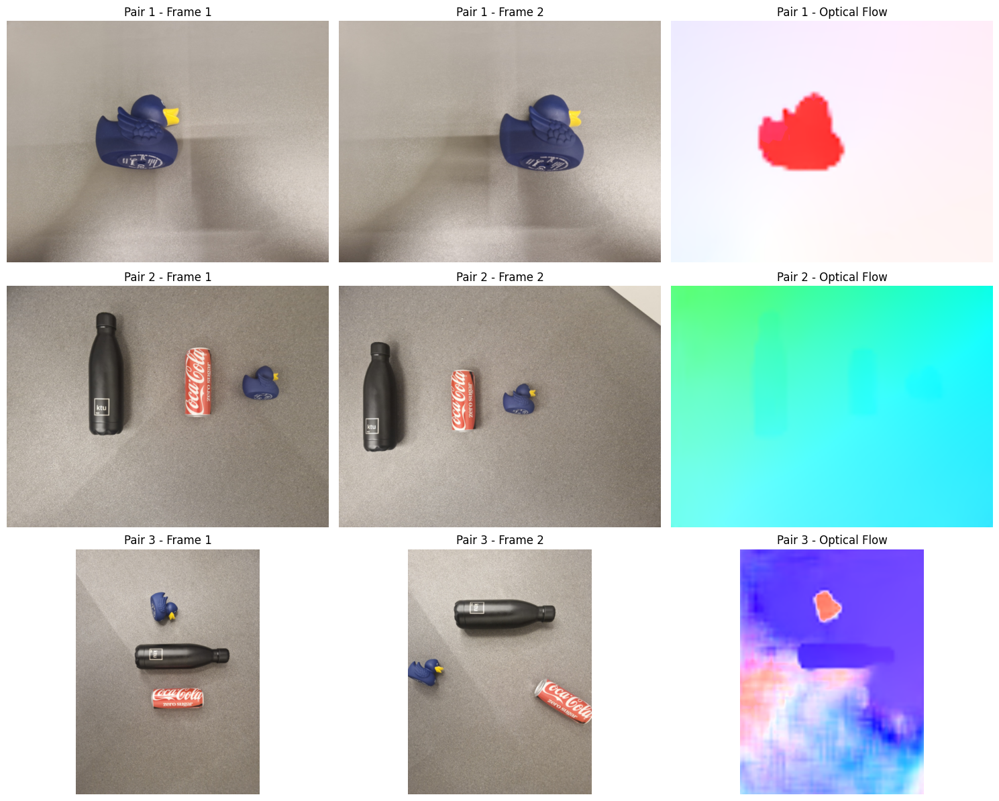

In [ ]:
from torchvision.utils import flow_to_image
import matplotlib.pyplot as plt

plt.figure(figsize=(15, 12))

for i in range(1, 4):
    frame1, frame2 = frames[f'pair{i}']
    flow = flows[f'pair{i}']

    images = [
        frame1,
        frame2,
        flow_to_image(flow)
    ]

    titles = ['Frame 1', 'Frame 2', 'Optical Flow']

    for j in range(3):
        plt.subplot(3, 3, (i-1)*3 + j + 1)
        plt.imshow(images[j].permute(1, 2, 0))
        plt.title(f'Pair {i} - {titles[j]}')
        plt.axis('off')

plt.tight_layout()
plt.show()

***average predicted movement***

In [ ]:
for i in range(1, 4):
    flow = flows[f'pair{i}']

    magnitude = torch.sqrt(flow[0]**2 + flow[1]**2)

    print(f"Pair {i}: Average motion = {magnitude.mean():.2f} pixels")

Pair 1: Average motion = 16.13 pixels
Pair 2: Average motion = 125.14 pixels
Pair 3: Average motion = 78.24 pixels


***Dense Optical Flow Magnitude Statistics***

In [ ]:
import numpy as np
import pandas as pd

statistics = []

for i in range(1, 4):
    flow = flows[f'pair{i}']

    magnitude = torch.sqrt(flow[0]**2 + flow[1]**2)

    statistics.append([
        f'Pair {i}',
        magnitude.mean().item(),
        magnitude.max().item()
    ])

table2 = pd.DataFrame(statistics, columns=[
    'Frame Pair',
    'Mean Flow (px)',
    'Maximum Flow (px)'
])

display(table2.round(2))

,Frame Pair,Mean Flow (px),Maximum Flow (px)
0,Pair 1,16.13,182.09
1,Pair 2,125.14,173.08
2,Pair 3,78.24,144.01


***Display images with pixel coordinates***

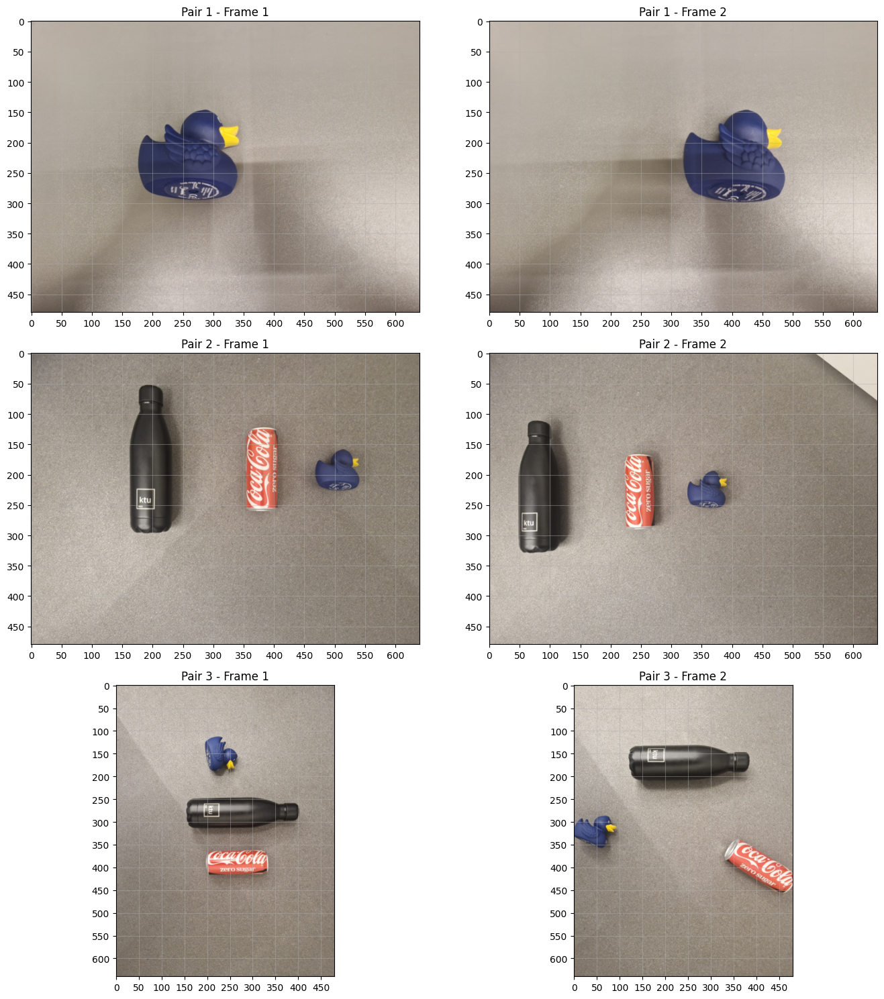

In [ ]:
plt.figure(figsize=(14, 15))

for i in range(1, 4):
    frame1, frame2 = frames[f'pair{i}']

    for j, frame in enumerate([frame1, frame2]):
        plt.subplot(3, 2, (i-1)*2 + j + 1)
        plt.imshow(frame.permute(1, 2, 0))

        h, w = frame.shape[1:]
        plt.xticks(range(0, w, 50))
        plt.yticks(range(0, h, 50))
        plt.grid(alpha=0.4)
        plt.title(f'Pair {i} - Frame {j+1}')

plt.tight_layout()
plt.show()

***manually measured positions***

In [ ]:
# Pair, Object, x1, y1, x2, y2

measurements = [
    (1, 'Duck', 255, 190, 420, 195),

    (2, 'Bottle', 195, 65, 85, 130),
    (2, 'Can', 385, 130, 245, 175),
    (2, 'Duck', 495, 190, 370, 215),

    (3, 'Bottle', 210, 270, 175, 160),
    (3, 'Can', 300, 390, 415, 410),
    (3, 'Duck', 255, 170, 60, 315)
]

***Verify the selected points***

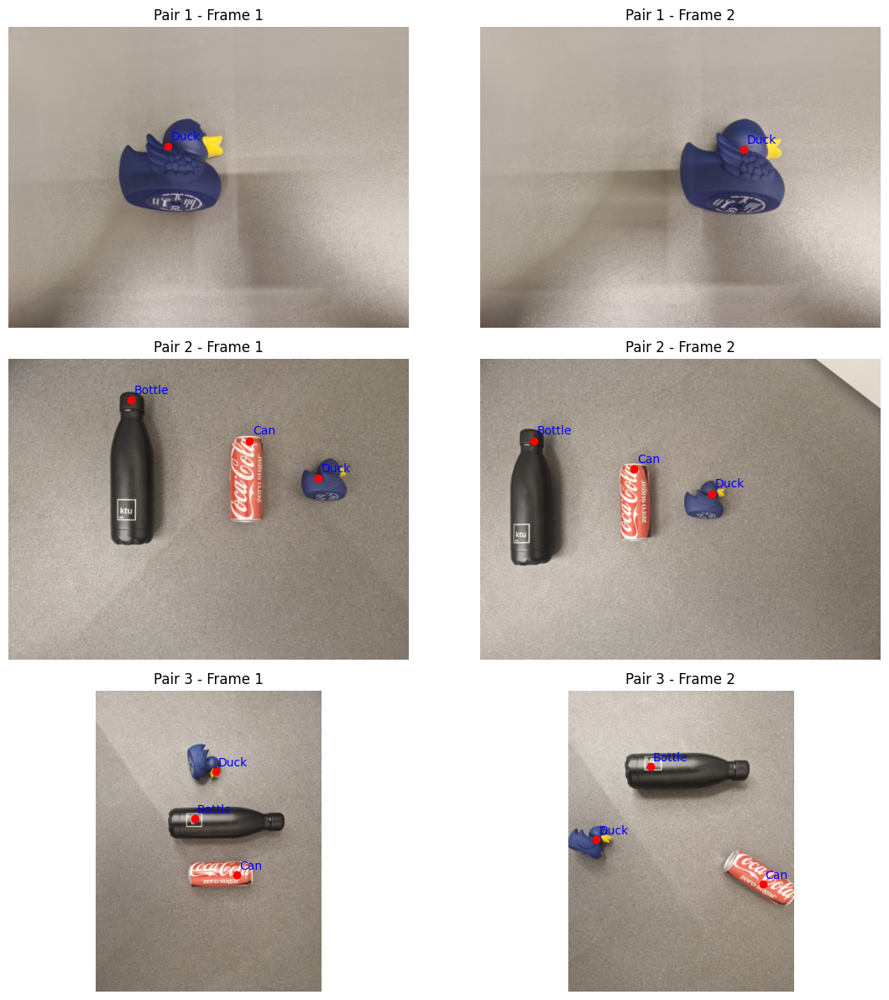

In [ ]:
plt.figure(figsize=(12, 12))

for i in range(1, 4):
    frame1, frame2 = frames[f'pair{i}']

    for j, frame in enumerate([frame1, frame2]):
        plt.subplot(3, 2, (i-1)*2 + j + 1)
        plt.imshow(frame.permute(1, 2, 0))

        for pair, obj, x1, y1, x2, y2 in measurements:
            if pair == i:
                x, y = (x1, y1) if j == 0 else (x2, y2)

                plt.plot(x, y, 'ro')
                plt.text(x+5, y-10, obj, color='blue')

        plt.title(f'Pair {i} - Frame {j+1}')
        plt.axis('off')

plt.tight_layout()
plt.show()

***Calculate manual displacement***

In [ ]:
for pair, obj, x1, y1, x2, y2 in measurements:
    dx = x2 - x1
    dy = y2 - y1

    print(f"Pair {pair} - {obj}: dx = {dx}, dy = {dy}")

Pair 1 - Duck: dx = 165, dy = 5
Pair 2 - Bottle: dx = -110, dy = 65
Pair 2 - Can: dx = -140, dy = 45
Pair 2 - Duck: dx = -125, dy = 25
Pair 3 - Bottle: dx = -35, dy = -110
Pair 3 - Can: dx = 115, dy = 20
Pair 3 - Duck: dx = -195, dy = 145


***Calculate Endpoint Error (EPE)***

In [ ]:
import numpy as np
import pandas as pd

results = []

for pair, obj, x1, y1, x2, y2 in measurements:
    flow = flows[f'pair{pair}']

    # Manual displacement
    manual_dx = x2 - x1
    manual_dy = y2 - y1

    # Predicted displacement
    region = flow[:, y1-2:y1+3, x1-2:x1+3]

    predicted_dx = region[0].median().item()
    predicted_dy = region[1].median().item()

    # Endpoint Error
    epe = np.sqrt(
        (manual_dx - predicted_dx)**2 +
        (manual_dy - predicted_dy)**2
    )

    results.append([
        pair, obj, manual_dx, manual_dy,
        predicted_dx, predicted_dy, epe
    ])

table3 = pd.DataFrame(results, columns=[
    'Pair', 'Object', 'Manual dx', 'Manual dy',
    'Predicted dx', 'Predicted dy', 'EPE (px)'
])

display(table3.round(2))

,Pair,Object,Manual dx,Manual dy,Predicted dx,Predicted dy,EPE (px)
0,1,Duck,165,5,139.94,1.94,25.25
1,2,Bottle,-110,65,-116.24,56.20,10.79
2,2,Can,-140,45,-140.50,41.81,3.23
3,2,Duck,-125,25,-148.07,33.91,24.73
4,3,Bottle,-35,-110,-28.59,-114.62,7.90
5,3,Can,115,20,-30.29,-45.53,159.39
6,3,Duck,-195,145,-6.28,-44.94,267.76


***Endpoint Error Evaluation***

In [ ]:
table4 = table3.groupby('Pair')['EPE (px)'].agg(
    ['count', 'mean', 'median', 'max']
)

table4.columns = [
    'Objects Evaluated',
    'Mean EPE (px)',
    'Median EPE (px)',
    'Maximum EPE (px)'
]

table4.loc['Overall'] = [
    len(table3),
    table3['EPE (px)'].mean(),
    table3['EPE (px)'].median(),
    table3['EPE (px)'].max()
]

display(table4.round(2))

,Objects Evaluated,Mean EPE (px),Median EPE (px),Maximum EPE (px)
Pair,,,,
1,1.0,25.25,25.25,25.25
2,3.0,12.91,10.79,24.73
3,3.0,145.01,159.39,267.76
Overall,7.0,71.29,24.73,267.76


***Motion Vector Visualization***

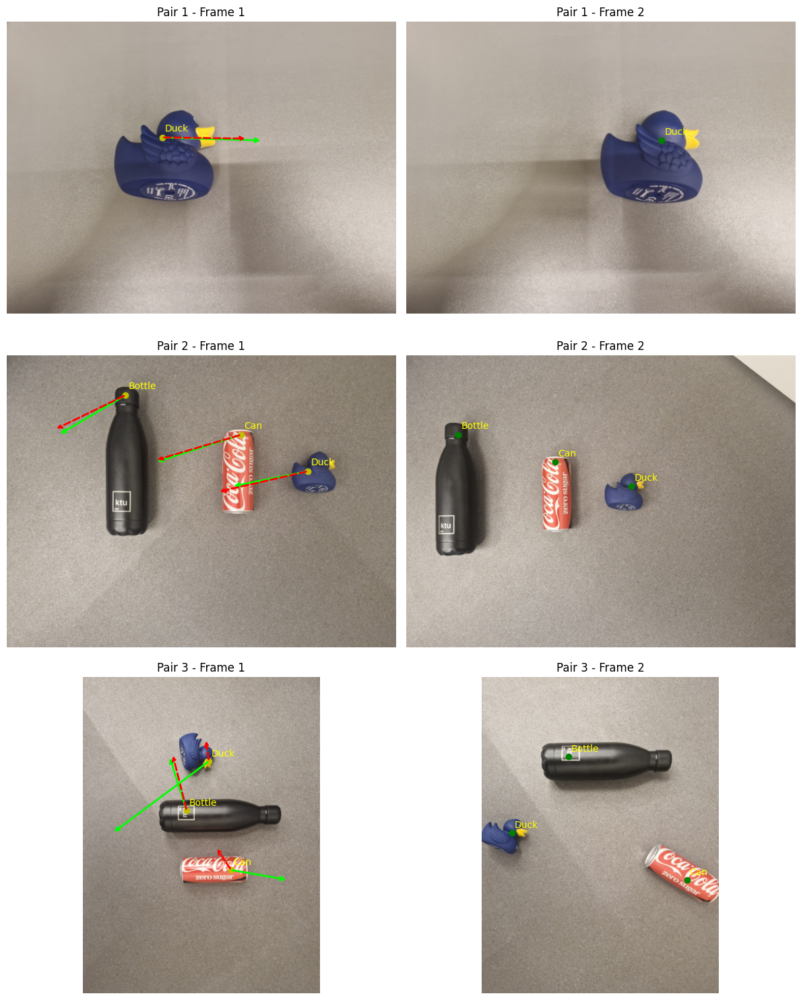

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 15))

for i in range(1, 4):
    frame1, frame2 = frames[f'pair{i}']

    # Frame 1 - Movement vectors
    plt.subplot(3, 2, 2*i - 1)
    plt.imshow(frame1.permute(1, 2, 0))

    for j, (pair, obj, x1, y1, x2, y2) in enumerate(measurements):
        if pair != i:
            continue

        dx = results[j][4]
        dy = results[j][5]

        # Starting point
        plt.plot(x1, y1, 'yo')

        # Manual movement - green solid arrow
        plt.annotate('', xy=(x2, y2), xytext=(x1, y1),
                     arrowprops=dict(arrowstyle='->', color='lime', lw=2))

        # Predicted movement - red dashed arrow
        plt.annotate('', xy=(x1+dx, y1+dy), xytext=(x1, y1),
                     arrowprops=dict(arrowstyle='->', color='red',
                                     linestyle='--', lw=2))

        plt.text(x1+5, y1-10, obj, color='yellow')

    plt.title(f'Pair {i} - Frame 1')
    plt.axis('off')

    # Frame 2 - Final positions
    plt.subplot(3, 2, 2*i)
    plt.imshow(frame2.permute(1, 2, 0))

    for pair, obj, x1, y1, x2, y2 in measurements:
        if pair == i:
            plt.plot(x2, y2, 'go')
            plt.text(x2+5, y2-10, obj, color='yellow')

    plt.title(f'Pair {i} - Frame 2')
    plt.axis('off')

plt.tight_layout()
plt.show()